# 08 — Evaluación de la prueba de prompting (sin usar el hold-out)

Se evalúan las respuestas del LLM contra las etiquetas reservadas de los **20 clientes de entrenamiento**. Una muestra de este tamaño es solamente exploratoria. No sirve para comparar estadísticamente contra AP de validación cruzada de los clasificadores entrenados.

Es importante registrar el identificador del modelo usado y la fecha de ejecución. No se utiliza `CHURN_FLAG` en los prompts ni se reentrena ningún modelo.

{
  "modelo_llm": "GPT-6 (ChatGPT, evaluación manual de fichas)",
  "fecha_utc": "2026-11-19T04:36:15.816410+00:00",
  "n_ejemplos": 20,
  "positivos_reales": 5,
  "negativos_reales": 15,
  "accuracy": 0.9,
  "precision_clase_abandona": 0.8,
  "recall_clase_abandona": 0.8,
  "f1_clase_abandona": 0.8,
  "matriz_confusion_orden_0_1": [
    [
      14,
      1
    ],
    [
      1,
      4
    ]
  ],
  "advertencia": "Prueba exploratoria, no validación cruzada ni métricas de holdout; no inferir beneficio empresarial."
}


,ejemplo,etiqueta_real_reservada,prediccion_llm,razon_breve,y_pred,acierto
0,1,1,ABANDONA,"Contrato mensual y solo 2 meses de antigüedad,...",1,1
1,2,0,PERMANECE,"Antigüedad de 52 meses, soporte técnico contra...",0,1
2,3,0,ABANDONA,"Contrato mensual, fibra óptica, cargo relativa...",1,0
3,4,0,PERMANECE,"Contrato anual, 23 meses de antigüedad y sopor...",0,1
4,5,0,PERMANECE,"Contrato anual, 62 meses de antigüedad y sopor...",0,1
5,6,0,PERMANECE,Contrato anual y 52 meses de antigüedad; la fa...,0,1
6,7,1,PERMANECE,"Contrato de dos años, 64 meses de antigüedad, ...",0,0
7,8,0,PERMANECE,"Contrato anual, 60 meses de antigüedad y pago ...",0,1
8,9,0,PERMANECE,"Contrato de dos años, 59 meses de antigüedad y...",0,1
9,10,0,PERMANECE,Contrato de dos años y cargo mensual bajo; la ...,0,1


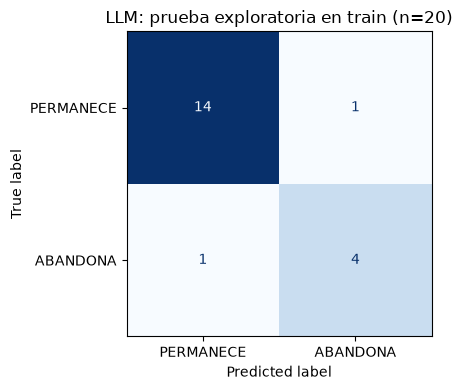

Resultados guardados en docs/llm_resultados_20_evaluados.csv y docs/llm_metricas_20.json


In [1]:
from pathlib import Path
import json, datetime
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

OUT = Path('/workspace/docs')
MODELO_LLM = 'GPT-6 (ChatGPT, evaluación manual de fichas)'  # Modificar según modelo realmente usado
FECHA_EVALUACION = datetime.datetime.now(datetime.timezone.utc).isoformat()
RUTA_RESPUESTAS = OUT/'llm_respuestas_20.csv'
RUTA_ETIQUETAS = OUT/'llm_etiquetas_20_reservadas.csv'

res = pd.read_csv(RUTA_RESPUESTAS, dtype={'prediccion_llm':str})
labels = pd.read_csv(RUTA_ETIQUETAS)
assert len(res) == len(labels) == 20
assert res['ejemplo'].is_unique and labels['ejemplo'].is_unique
res['prediccion_llm'] = res['prediccion_llm'].str.upper().str.strip()
assert res['prediccion_llm'].isin(['ABANDONA','PERMANECE']).all(), 'Completa las 20 predicciones antes de evaluar.'

tabla = labels.merge(res, on='ejemplo', how='inner', validate='one_to_one')
tabla['y_pred'] = tabla['prediccion_llm'].eq('ABANDONA').astype(int)
tabla['acierto'] = tabla['y_pred'].eq(tabla['etiqueta_real_reservada']).astype(int)
y_true, y_pred = tabla['etiqueta_real_reservada'], tabla['y_pred']
matriz = confusion_matrix(y_true,y_pred,labels=[0,1])
metricas = {
    'modelo_llm': MODELO_LLM,
    'fecha_utc': FECHA_EVALUACION,
    'n_ejemplos': len(tabla),
    'positivos_reales': int(y_true.sum()),
    'negativos_reales': int((y_true==0).sum()),
    'accuracy': float(accuracy_score(y_true,y_pred)),
    'precision_clase_abandona': float(precision_score(y_true,y_pred,zero_division=0)),
    'recall_clase_abandona': float(recall_score(y_true,y_pred,zero_division=0)),
    'f1_clase_abandona': float(f1_score(y_true,y_pred,zero_division=0)),
    'matriz_confusion_orden_0_1': matriz.tolist(),
    'advertencia': 'Prueba exploratoria, no validación cruzada ni métricas de holdout; no inferir beneficio empresarial.'
}
print(json.dumps(metricas,indent=2,ensure_ascii=False))
display(tabla)
tabla.to_csv(OUT/'llm_resultados_20_evaluados.csv',index=False,encoding='utf-8-sig')
(OUT/'llm_metricas_20.json').write_text(json.dumps(metricas,indent=2,ensure_ascii=False),encoding='utf-8')

disp = ConfusionMatrixDisplay(matriz, display_labels=['PERMANECE','ABANDONA'])
fig, ax = plt.subplots(figsize=(5,4))
disp.plot(ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title('LLM: prueba exploratoria en train (n=20)')
plt.tight_layout()
fig.savefig(OUT/'llm_matriz_confusion_20.png',dpi=170)
plt.show()
print('Resultados guardados en docs/llm_resultados_20_evaluados.csv y docs/llm_metricas_20.json')